In [20]:
from Model import Pick
import numpy as np
from PlotUtils import splt, errsPlot as plt
from Model.utilities import mean
from Model import Levels
from tqdm.auto import tqdm

In [38]:
n_g = 2.687e25
T_g = 300
f_e = 10**-5
T_e = 1.3

In [39]:
def scanrange( midval ):
    if( midval == 300 ):
        return np.logspace( np.log10( 150 ), np.log10( 600 ), 100 )
    return np.logspace( np.log10( midval ) - 1, np.log10( midval ) + 1, 100 )

In [40]:
picks = [ Pick.Pick() for i in range(100) ]

In [41]:
lv = Levels.Levels()
i_2p6 = lv.ID( '2p6' )
i_2p10 = lv.ID( '2p10' )

def get_ratio( pick: Pick.Pick, n_g, f_e, T_e, T_g ):
    n = pick.getEquilibrium( n_g, f_e, T_e, T_g )
    return n[i_2p6] / n[i_2p10]

def get_avg_ratio( n_g, f_e, T_e, T_g ):
    return mean( [ get_ratio( pick, n_g, f_e, T_e, T_g ) for pick in picks ] )

In [42]:
n_g_scan = [ get_avg_ratio( i, f_e, T_e, T_g ) for i in tqdm( scanrange( n_g ) ) ]
f_e_scan = [ get_avg_ratio( n_g, i, T_e, T_g ) for i in tqdm( scanrange( f_e ) ) ]
T_e_scan = [ get_avg_ratio( n_g, f_e, i, T_g ) for i in tqdm( scanrange( T_e ) ) ]
T_g_scan = [ get_avg_ratio( n_g, f_e, T_e, i ) for i in tqdm( scanrange( T_g ) ) ]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

Text(0.5, 0, 'T_g')

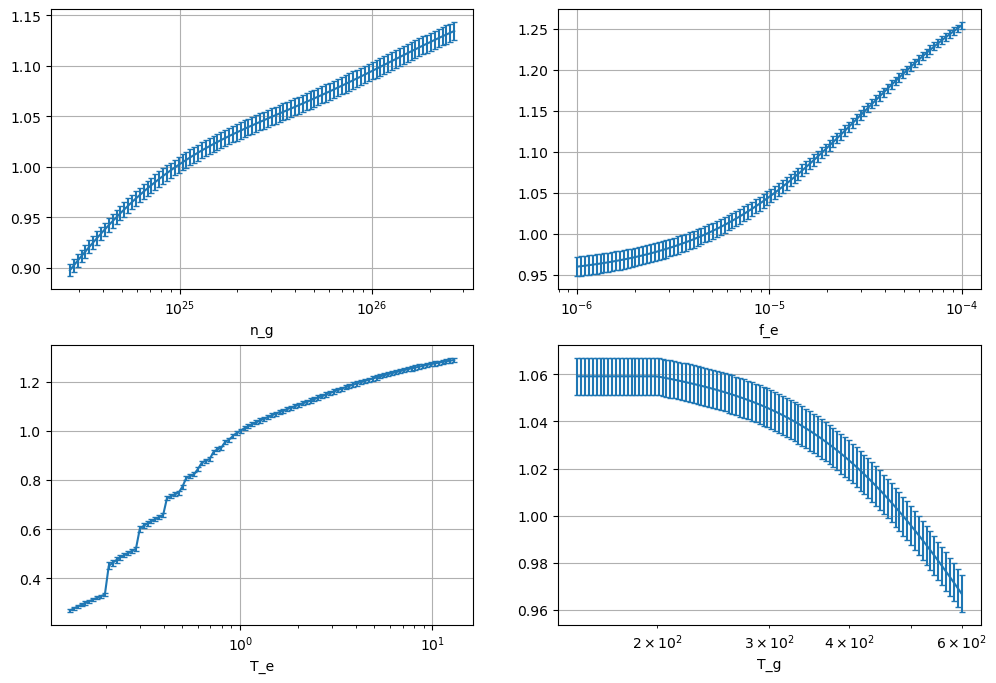

In [43]:
splt.init(2,2,True)

plt.plot( scanrange( n_g ), n_g_scan )
plt.xscale('log')
plt.xlabel('n_g')

splt.next()
plt.plot( scanrange( f_e ), f_e_scan )
plt.xscale('log')
plt.xlabel('f_e')

splt.next()
plt.plot( scanrange( T_e ), T_e_scan )
plt.xscale('log')
plt.xlabel('T_e')

splt.next()
plt.plot( scanrange( T_g ), T_g_scan )
plt.xscale('log')
plt.xlabel('T_g')

# splt.export( 'C01_2p6_2p10_ratio' )